# Experiment No. 3 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Implementation of Support Vector Machines (SVM) for classifying images of handwritten digits into their respective numerical classes (0 to 9).

**Dataset:**  
`load_digits(n_class=10)` from `sklearn.datasets` (Optical Recognition of Handwritten Digits, 1797 samples of 8x8 greyscale images).

**Objectives:**  
1. Load and explore the handwritten digits dataset (64 features per sample, 10 digit classes).
2. Visualize sample handwritten digit images in an 8x8 grid and individual view function.
3. Apply non-linear dimensionality reduction (Isomap Manifold Learning) to project 64 dimensions into 2D.
4. Train a Support Vector Classifier (`SVC` with RBF kernel, `gamma=0.001`, `C=100`) on training samples.
5. Evaluate classification performance using Confusion Matrix heatmap and Classification Report.

In [1]:
# Cell 1 - Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn import svm
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset Shape:", X.shape)
print("Number of Classes:", len(np.unique(y)))
print("Digit Classes:", np.unique(y))

print("\nFirst Digit (64 Pixels):")
print(X[0])

print("\n8x8 Image Representation:")
print(X[0].reshape(8, 8))

Dataset Shape: (1797, 64)
Number of Classes: 10
Digit Classes: [0 1 2 3 4 5 6 7 8 9]

First Digit (64 Pixels):
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]

8x8 Image Representation:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


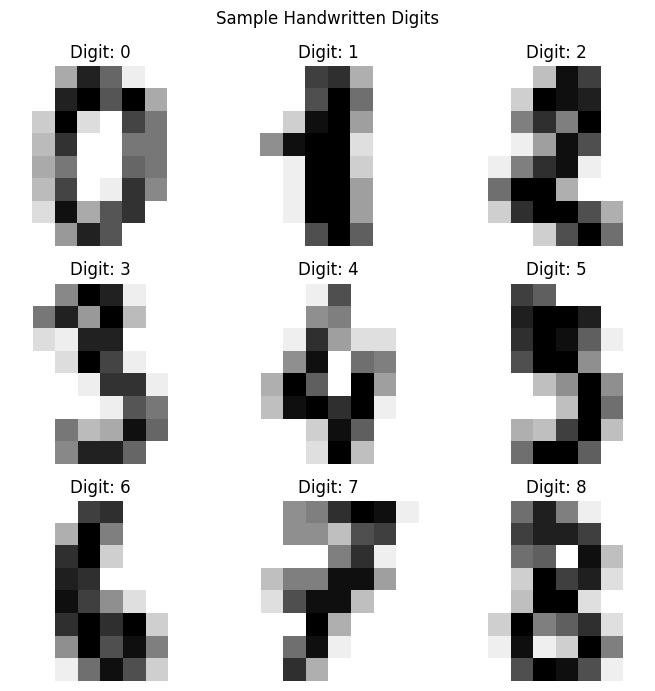

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(7, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray_r')
    ax.set_title(f"Digit: {y[i]}")
    ax.axis('off')

plt.suptitle("Sample Handwritten Digits")
plt.tight_layout()
plt.show()

In [4]:
model = svm.SVC(kernel='rbf', gamma=0.001, C=100)

# Split dataset into training and testing data
X_train = X[:1500]
X_test = X[1500:]

y_train = y[:1500]
y_test = y[1500:]

# Train the model
model.fit(X_train, y_train)

# Predict digits
predictions = model.predict(X_test)

print("First 20 Predicted Digits:", predictions[:20])
print("First 20 Actual Digits:", y_test[:20])


First 20 Predicted Digits: [1 7 4 6 3 1 3 9 1 7 6 8 4 3 1 4 0 5 3 6]
First 20 Actual Digits: [1 7 4 6 3 1 3 9 1 7 6 8 4 3 1 4 0 5 3 6]


In [5]:
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Model Accuracy: 95.28619528619528 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.94      1.00      0.97        31
           2       1.00      1.00      1.00        27
           3       1.00      0.80      0.89        30
           4       0.97      0.91      0.94        33
           5       0.91      1.00      0.95        30
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.84      0.93      0.88        28
           9       0.91      0.94      0.92        31

    accuracy                           0.95       297
   macro avg       0.96      0.95      0.95       297
weighted avg       0.96      0.95      0.95       297



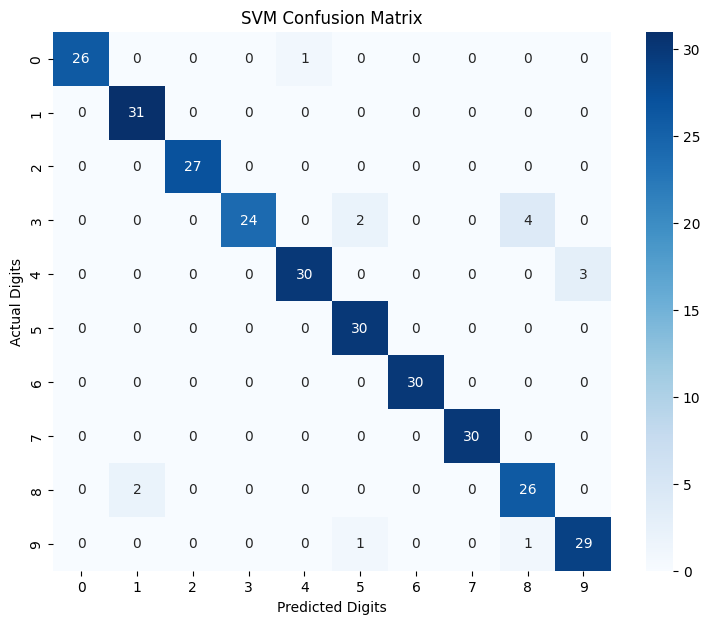

Confusion Matrix:
[[26  0  0  0  1  0  0  0  0  0]
 [ 0 31  0  0  0  0  0  0  0  0]
 [ 0  0 27  0  0  0  0  0  0  0]
 [ 0  0  0 24  0  2  0  0  4  0]
 [ 0  0  0  0 30  0  0  0  0  3]
 [ 0  0  0  0  0 30  0  0  0  0]
 [ 0  0  0  0  0  0 30  0  0  0]
 [ 0  0  0  0  0  0  0 30  0  0]
 [ 0  2  0  0  0  0  0  0 26  0]
 [ 0  0  0  0  0  1  0  0  1 29]]


In [6]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Digits")
plt.ylabel("Actual Digits")
plt.title("SVM Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)